In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print("💻 ローカル / ホスト環境で実行中。ルート:", repo_root)


💻 ローカル / ホスト環境で実行中。ルート: /home/student/Documents/GitHub/study-mikanos


# 7.4 割り込み記述子の設定 (`Configuring IDT Descriptors`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/7/7.4_Configuring_IDT_Descriptors.ipynb)
![Language](https://img.shields.io/badge/Language-C%2B%2B20%20%7C%20Python%203.10%2B-blue.svg)
![Architecture](https://img.shields.io/badge/Architecture-x86--64%20%7C%20Long%20Mode-orange.svg)
![Target Tag](https://img.shields.io/badge/Tag-osbook__day07a-green.svg)

---

## 📖 本節の概要と学習目標

前節（7.1〜7.3）では、割り込みの基本的意義、`__attribute__((interrupt))` によるハンドラ関数のスタック保全と `IRETQ` 復帰、そして x86-64 の 256 個のベクタ空間における xHCI 割り込みベクタ番号 `0x40` (十進数 64) の設計を学びました。

しかし、ハンドラ関数（`IntHandlerXHCI`）を C++ で定義し、ベクタ番号を `0x40` に決めただけでは、CPU は依然として割り込みを処理できません。なぜなら、**「ベクタ 0x40 の割り込みを受信したとき、どのメモリ番地（RIP）の関数へジャンプすべきか」というハードウェア対応関係を、CPU コアにまだ教えていないから**です。

```
【これまでの実装状態】
  [xHCI コントローラ] ──(MSIベクタ 0x40)──> [CPU コア] ──? (どこへ行けばいいのか不明!)
                                                   │
                                                   ▼ #GP (一般保護例外) または ハング
  [メモリ上の関数] IntHandlerXHCI() (孤立した状態)
```

本節（7.4 割り込み記述子の設定）では、このミッシングリンクを結ぶ CPU の中核データ構造 **IDT (Interrupt Descriptor Table: 割り込み記述子表)** と、それを CPU 内部レジスタに登録する **`LIDT` (Load IDTR)** 命令を徹底的に解剖します。

### 🎯 到達目標
1. **割り込み記述子表 (IDT) の役割と構造の完全理解**:
   - 256 個のエントリから成る配列であり、ベクタ番号 $i$ に対応するハンドラ情報が `idt[i]` に格納される仕組み。
2. **16バイト（128ビット）割り込みゲート記述子のビット詳細導出**:
   - 64ビット仮想アドレスがなぜ 3 分割（`offset_low`, `offset_middle`, `offset_high`）されて格納されるのか（x86 歴史的互換性）。
   - コードセグメントセレクタ（CS）、IST（Interrupt Stack Table）、Type（0xE: 割り込みゲート）、DPL（特権レベル）、P（有効ビット）の厳密なビット配置。
   - MikanOS における属性値 `0x8E00` の数理導出。
3. **C++ による型安全な記述子データ構造の実装**:
   - `union InterruptDescriptorAttribute` と packed ビットフィールド構造体。
   - `MakeIDTAttr` ヘルパー関数と `SetIDTEntry` ビットシフト関数。
4. **`LIDT` 命令と `LoadIDT` アセンブリ関数の動作原理**:
   - 10バイト（80ビット）の IDTR レジスタ構造（`limit` 16ビット + `base` 64ビット）。
   - `sizeof(idt) - 1 = 4095 (0x0FFF)` を limit に設定する数学的理由（最大有効オフセット）。
   - C++ とアセンブリの連携によるハードウェア IDTR レジスタへの一括ロード。
5. **CPU による割り込みディスパッチの全ハードウェアシーケンスのトレース**:
   - ベクタ番号 $0	ext{x}40 	imes 16$ バイト計算からエントリフェッチ、スタック自動退避、IF フラグクリア、ハンドラジャンプまでの精密な追跡。


---

## 1. 割り込み記述子表（IDT: Interrupt Descriptor Table）とは何か？

### 1.1 割り込みベクタとハンドラを結ぶルーティングテーブル

x86-64 アーキテクチャにおいて、CPU が外部ハードウェア割り込みや例外、ソフトウェア割り込み（`INT n`）を受け取った際、**どのメモリ番地に配置されたハンドラコードを実行すべきか** を定義したメモリ上の配列テーブルを **IDT (Interrupt Descriptor Table: 割り込み記述子表)** と呼びます。

IDT は、0 から 255 までの各割り込みベクタ番号に対応する **割り込み記述子（ゲート記述子）** を 256 個並べた巨大な配列です：

$$\text{IDT} = [\text{Desc}_0, \text{Desc}_1, \text{Desc}_2, \dots, \text{Desc}_{255}]$$

CPU がベクタ番号 $N$ の割り込みを受け取ると、CPU ハードウェアは内部レジスタ **IDTR (IDT Register)** に保持された先頭アドレスを基準に、オフセット $N \times (\text{記述子のバイトサイズ})$ 番地を自動参照します。

```text
 割り込み発生 (ベクタ N)
         │
         ▼
 [CPU ハードウェア]
   │ IDTR.base + N * 16
   ▼
 ┌──────────────────────────────────────────────┐ 0x0000 (IDTR.base)
 │ エントリ 0  : #DE (除算エラー例外ハンドラ)    │
 ├──────────────────────────────────────────────┤
 │ エントリ 1  : #DB (デバッグ例外ハンドラ)      │
 ├──────────────────────────────────────────────┤
 │ ...                                          │
 ├──────────────────────────────────────────────┤
 │ エントリ 0x40 (64): IntHandlerXHCI() ◄───────┼─ ここをハードウェアが自動フェッチ!
 ├──────────────────────────────────────────────┤
 │ ...                                          │
 ├──────────────────────────────────────────────┤
 │ エントリ 255: ユーザー定義割り込みハンドラ   │
 └──────────────────────────────────────────────┘ IDTR.base + 4095
```

---

### 1.2 リアルモードの IVT と 64ビットモードの IDT の違い

x86 の歴史において、割り込みの分岐テーブルは以下のように進化してきました：

| 動作モード | テーブル名称 | 各エントリのサイズ | エントリの内容 | テーブル全体のサイズ |
|:---|:---|:---:|:---|:---:|
| **16-bit リアルモード** | **IVT** (*Interrupt Vector Table*) | **4 バイト** | 16ビットセグメント + 16ビットオフセット (物理 `0x00000` 固定) | $256 \times 4\text{B} = 1{,}024\text{B}$ (1 KiB) |
| **32-bit プロテクトモード** | **IDT** (*Interrupt Descriptor Table*) | **8 バイト** | 16ビットセレクタ + 32ビットオフセット + 属性 (IDTR任意配置) | $256 \times 8\text{B} = 2{,}048\text{B}$ (2 KiB) |
| **64-bit Long Mode (MikanOS)** | **IDT** (*Interrupt Descriptor Table*) | **16 バイト** | 16ビットセレクタ + 64ビットオフセット + IST/属性 + 予約 | $256 \times 16\text{B} = 4{,}096\text{B}$ (4 KiB) |

> [!IMPORTANT]
> **なぜ 64ビットモードでは 1 エントリが 16 バイト (128 ビット) なのか？**
> 64ビット Long Mode では、メモリ空間のアドレス（ポインタ / RIP）が 64 ビット（8 バイト）に拡大されました。
> 32ビット時代の 8 バイト記述子では 64 ビットのアドレスを収容できないため、Intel は記述子のサイズを **倍の 16 バイト** に拡張し、上位 32 ビットのアドレスと TSS スタック切り替え用 IST（*Interrupt Stack Table*）フィールドを追加しました。


---

## 2. 16バイト（128ビット）割り込みゲート記述子の完全解剖

x86-64 の 64ビット割り込みゲート記述子（*64-bit Interrupt Gate Descriptor*）は、正確に 16 バイト（128 ビット）の固定長データ構造です。

```text
 127                             96 95                             64
 ┌─────────────────────────────────┬─────────────────────────────────┐
 │        Reserved (予約領域: 0)   │    offset_high (RIP bits 32..63) │
 ├────────────────┬─┬──┬─┬────┬─┬──┴┬────────────────┬────────────────┤
 │ offset_middle  │P│DPL│0│Type│0│IST│segment_selector│   offset_low   │
 │ (RIP bits16..31│ │   │ │    │ │  │ (コードセグメント│(RIP bits 0..15)│
 └────────────────┴─┴──┴─┴────┴─┴───┴────────────────┴────────────────┘
 63             48 47  44 43 40   32 31            16 15             0
```

### 2.1 なぜ 64ビットアドレスが 3 分割（low / mid / high）されているのか？

64ビットのハンドラ関数アドレス（仮想 RIP）は、記述子内で 1 箇所にまとまっておらず、以下の 3 つのフィールドにバラバラに分割して格納されます：
1. **`offset_low`** (bits 0..15): アドレスのビット $0 \sim 15$（下位 16 ビット）
2. **`offset_middle`** (bits 48..63): アドレスのビット $16 \sim 31$（中位 16 ビット）
3. **`offset_high`** (bits 64..95): アドレスのビット $32 \sim 63$（上位 32 ビット）

この奇妙な分割構造は、**x86 プロセッサの後方互換性（Backward Compatibility）の歴史** に起因しています：
- **80286 (16-bit)**: `offset_low` (16bit) のみ存在。
- **80386 (32-bit)**: 32ビットアドレスに対応するため、記述子後半に `offset_middle` (16bit) を追加。
- **x86-64 (64-bit)**: 64ビットアドレスに対応するため、32ビット記述子の後ろにさらに 8 バイトを付け足し、そこに `offset_high` (32bit) と `reserved` (32bit) を追加。

過去の CPU 向けに設計されたビット配置（セグメントセレクタや属性ビットの位置）を極力壊さずに拡張を重ねた結果、現代の x86-64 でも 64ビットアドレスを 3 つに分解して格納・復元するビット演算が必要になっています。

---

### 2.2 各ビットフィールドのハードウェア仕様

| フィールド名 | ビット範囲 | サイズ | MikanOS での設定値 | 役割・ハードウェア仕様 |
|:---|:---:|:---:|:---:|:---|
| **`offset_low`** | $0 \sim 15$ | 16 bits | `handler & 0xFFFF` | ハンドラ関数の仮想先頭アドレスの下位 16 ビット。 |
| **`segment_selector`** | $16 \sim 31$ | 16 bits | `GetCS()` (`0x0008`) | ハンドラコードを実行するコードセグメントセレクタ（CS）。カーネル空間（Ring 0）の CS を指定。 |
| **`IST`** (*Interrupt Stack Table*) | $32 \sim 34$ | 3 bits | `0` (通常スタック) | TSS 内の専用割り込みスタック表（IST1〜IST7）のインデックス。`0` の場合は既存の RSP をそのまま利用（第21章で詳細解説）。 |
| **Reserved** | $35 \sim 39$ | 5 bits | `0` | 常に 0 でなければならない予約ビット。 |
| **`Type`** (*Gate Type*) | $40 \sim 43$ | 4 bits | `0xE` (`14`: Interrupt Gate) | ゲート記述子の種別。`0xE` は 64-bit Interrupt Gate（IF フラグ自動クリア）、`0xF` は 64-bit Trap Gate（IF 維持）。 |
| **`S`** (*System*) | $44$ | 1 bit | `0` | 記述子タイプ。`0` = システム記述子（ゲート記述子はすべてシステム記述子）。 |
| **`DPL`** (*Descriptor Privilege Level*) | $45 \sim 46$ | 2 bits | `0` (Ring 0) | 記述子特権レベル。`INT n` などのソフトウェア命令で起動を許可する最小特権レベル（0: カーネル, 3: ユーザー）。 |
| **`P`** (*Present*) | $47$ | 1 bit | `1` (有効) | セグメント存在フラグ。`1` で記述子が有効。`0` のエントリで割り込みが発生すると `#NP` (Segment Not Present, ベクタ11) 例外。 |
| **`offset_middle`** | $48 \sim 63$ | 16 bits | `(handler >> 16) & 0xFFFF` | ハンドラ関数の仮想先頭アドレスの中位 16 ビット（bits 16..31）。 |
| **`offset_high`** | $64 \sim 95$ | 32 bits | `handler >> 32` | ハンドラ関数の仮想先頭アドレスの上位 32 ビット（bits 32..63）。 |
| **`reserved`** | $96 \sim 127$ | 32 bits | `0x00000000` | 将来のプロセッサ拡張用予約領域。Intel SDM 仕様により必ず 0 でクリアする。 |

---

### 2.3 属性値 `0x8E00` の数理導出

ビット 32〜47 の 16 ビット（属性ワード `attr`）を抽出し、MikanOS の設定値を 2 進数で並べてみましょう：

$$\begin{aligned}
\text{bit } 15 \text{ (P)} & = 1 \quad (\text{Present}) \\
\text{bit } 14..13 \text{ (DPL)} & = 00_2 \quad (\text{Ring 0}) \\
\text{bit } 12 \text{ (S)} & = 0 \quad (\text{System}) \\
\text{bit } 11..8 \text{ (Type)} & = 1110_2 = 0\text{xE} \quad (\text{64-bit Interrupt Gate}) \\
\text{bit } 7..3 & = 00000_2 \quad (\text{Reserved}) \\
\text{bit } 2..0 \text{ (IST)} & = 000_2 \quad (\text{Current RSP})
\end{aligned}$$

これを 16 ビットの 2 進数および 16 進数としてまとめると：

$$\text{attr.data} = \underbrace{1000}_{8} \; \underbrace{1110}_{\text{E}} \; \underbrace{0000}_{0} \; \underbrace{0000}_{0} = \mathbf{0\text{x}8E00}$$

この `0x8E00` という値が、MikanOS の標準カーネル割り込みゲート属性の正体です。


---

## 3. 割り込みゲート記述子 16バイト詳細レイアウト図 (Figure 7.07)

以下の図版（Figure 7.07）は、16 バイト（128 ビット）記述子の各ビット位置、型、および MikanOS での設定値・役割を完全可視化したものです。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:25272: UserWarning: Glyph 36890 (\N{CJK UNIFIED IDEOGRAPH-901A}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(output_path, dpi=300, bbox_inches="tight")
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:25272: UserWarning: Glyph 24120 (\N{CJK UNIFIED IDEOGRAPH-5E38}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(output_path, dpi=300, bbox_inches="tight")
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:25272: UserWarning: Glyph 12473 (\N{KATAKANA LETTER SU}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(output_path, dpi=300, bbox_inches="tight")
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:25272: UserWarning: Glyph 12479 (\N{KATAKANA LETTER TA}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(output_path, dpi=300, bbox_inches="tight")
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:25272: UserWarning: Glyph 12483 (\N{KATAKANA LETTER SMALL TU})

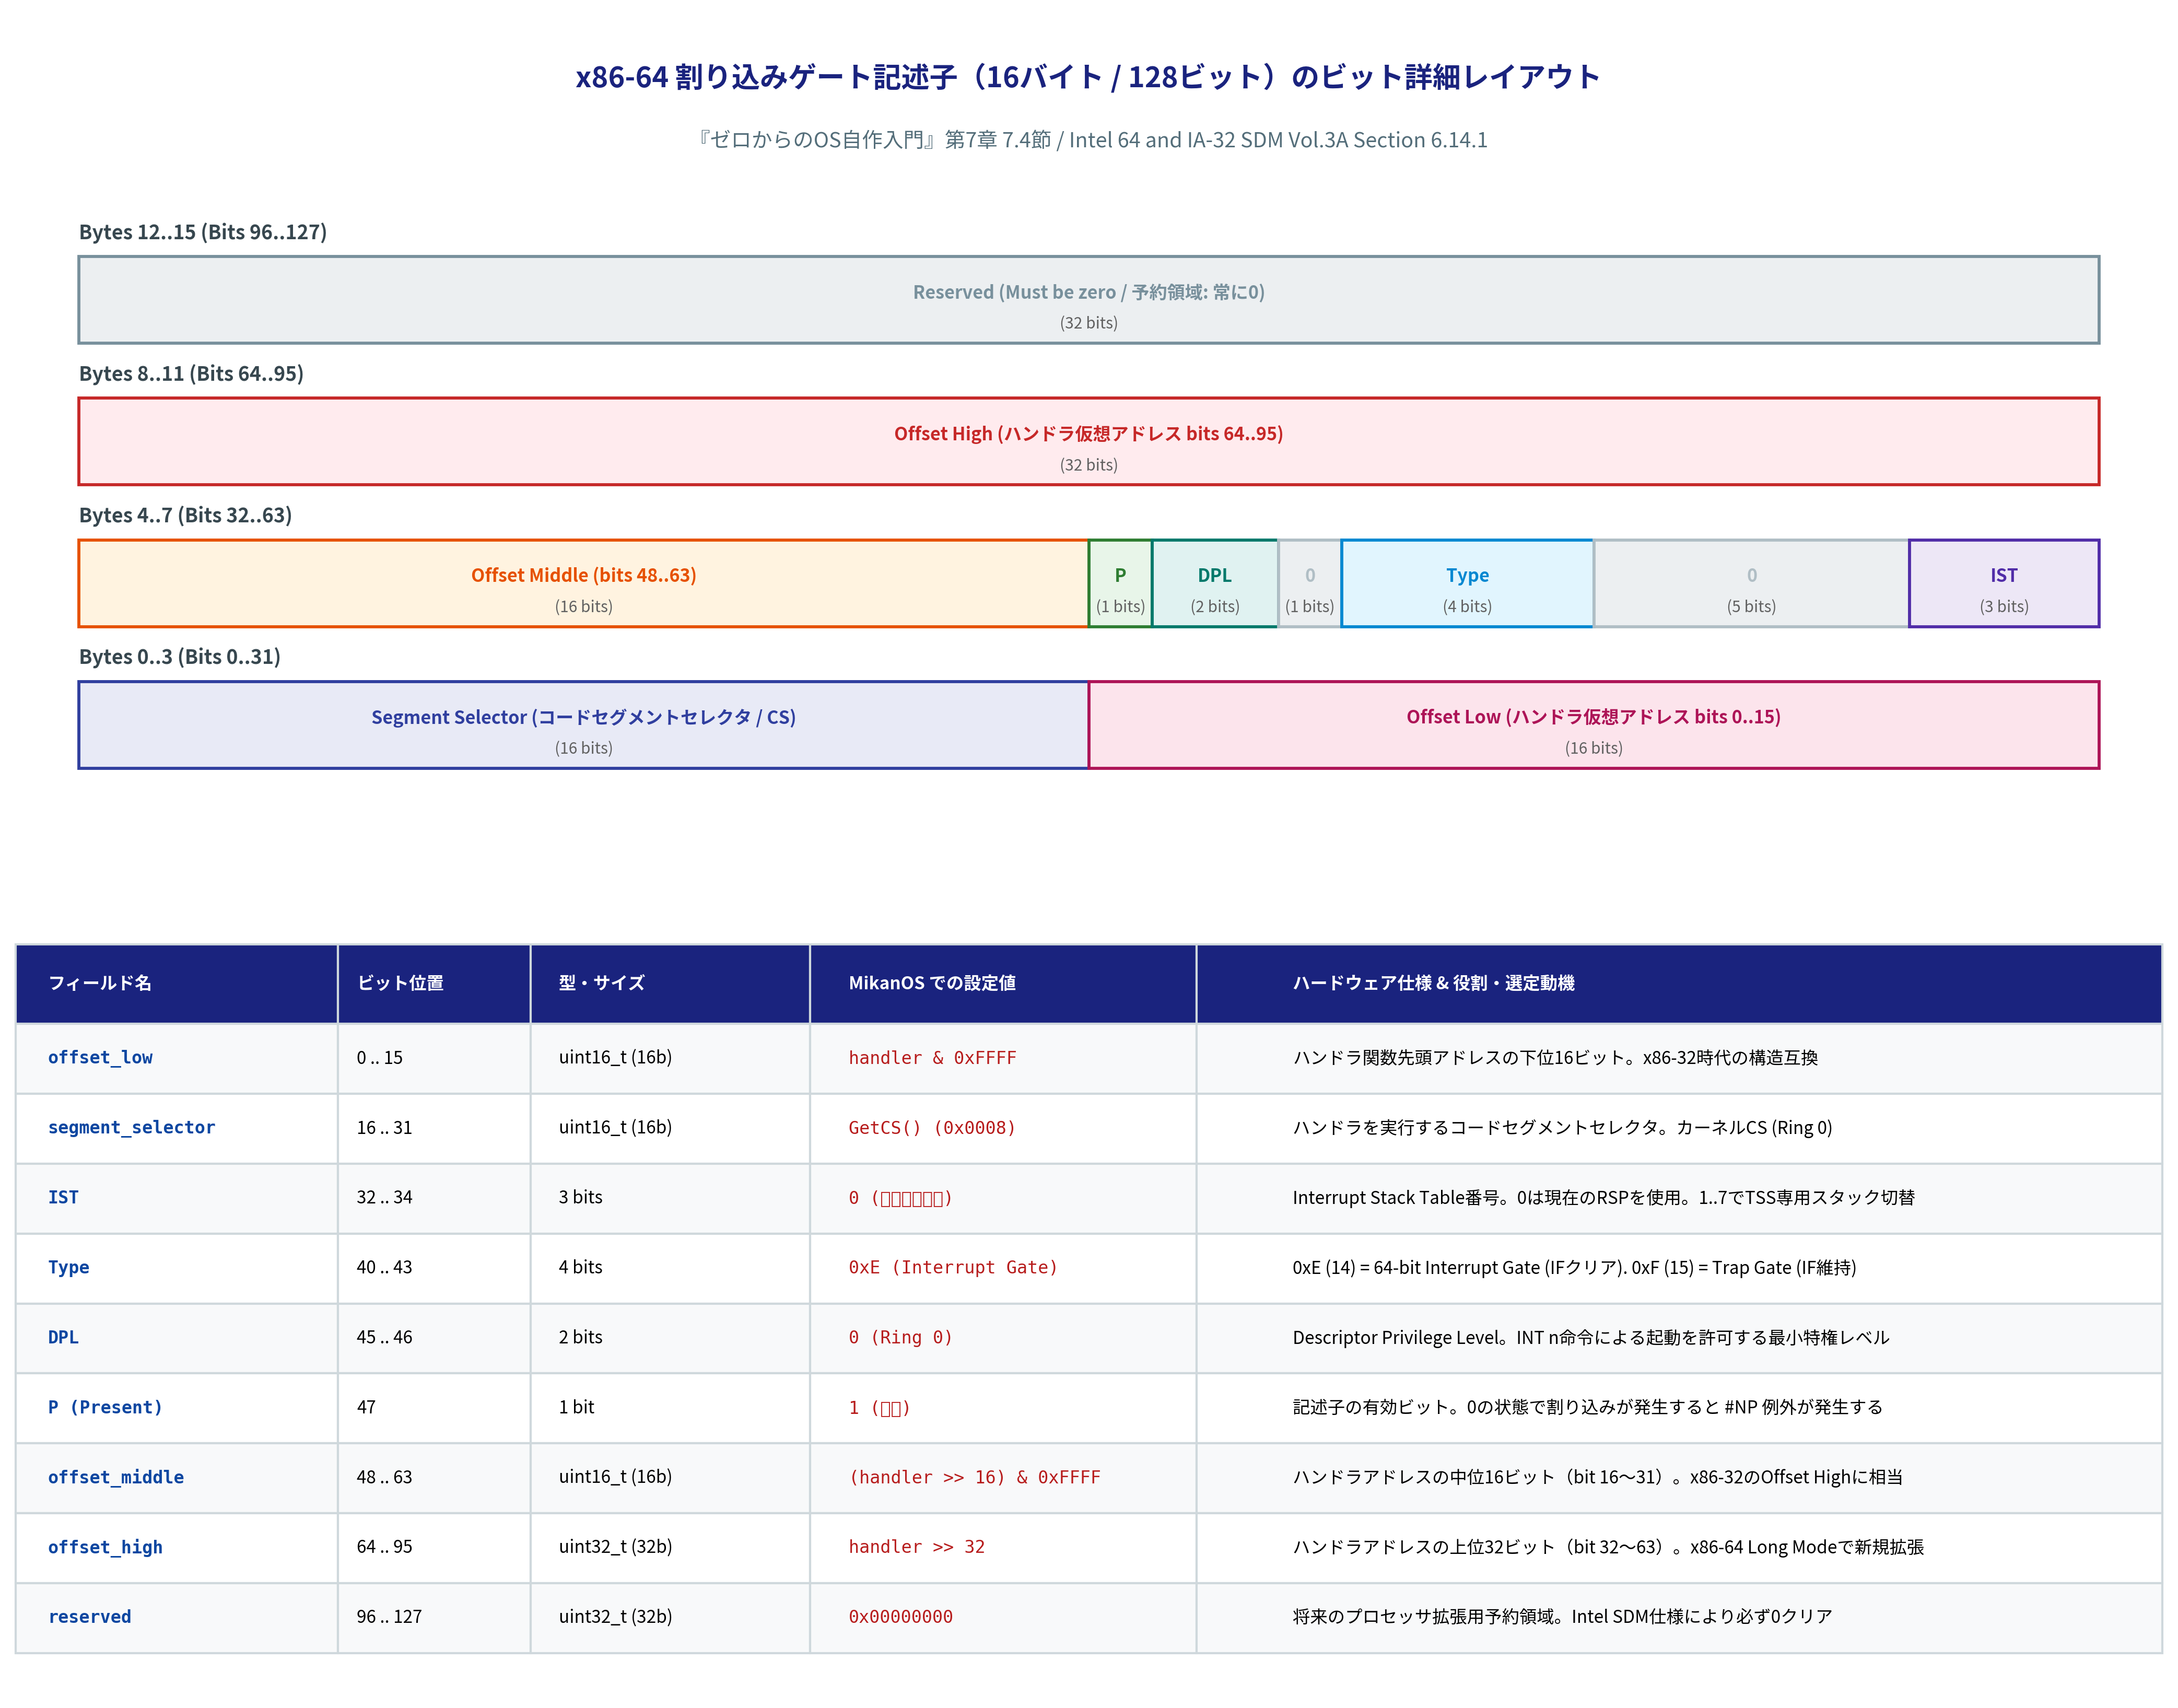

In [2]:
# === Figure 7.07: 16バイト IDT ゲート記述子の詳細レイアウト図の生成 & 表示 ===
from pathlib import Path
from IPython.display import Image, display
from common import plot_idt_descriptor_16byte_layout

fig7_07_path = Path("result/fig7_07_idt_descriptor_16byte_layout.png")
plot_idt_descriptor_16byte_layout(fig7_07_path)

display(Image(filename=str(fig7_07_path)))


---

## 4. C++ による型安全な記述子データ構造の実装 (`osbook_day07a`)

MikanOS では、ハードウェア仕様の 16 バイト記述子を、C++ の **共用体（`union`）** と **ビットフィールド（Bitfield）**、および **属性 `__attribute__((packed))`** を組み合わせて、極めて美しく型安全に表現しています。

### 4.1 記述子種別 `DescriptorType` (`kernel/interrupt.hpp`)

記述子タイプのマジックナンバー（`14` や `15`）の直書きを防ぐため、`enum class` を定義します：

```cpp
enum class DescriptorType {
  kUpper8Bytes   = 0,
  kLDT           = 2,
  kTSSAvailable  = 9,
  kTSSBusy       = 11,
  kCallGate      = 12,
  kInterruptGate = 14, // 0xE: 64-bit 割り込みゲート (IF自動クリア)
  kTrapGate      = 15, // 0xF: 64-bit トラップゲート (IF維持)
};
```

---

### 4.2 属性共用体 `InterruptDescriptorAttribute` (`kernel/interrupt.hpp`)

```cpp
union InterruptDescriptorAttribute {
  uint16_t data;
  struct {
    uint16_t interrupt_stack_table : 3;      // bits 0..2: IST
    uint16_t : 5;                           // bits 3..7: 予約 (無名ビットフィールドでパディング)
    DescriptorType type : 4;                // bits 8..11: 記述子種別
    uint16_t : 1;                           // bit 12: S フラグ (0)
    uint16_t descriptor_privilege_level : 2;// bits 13..14: DPL (0..3)
    uint16_t present : 1;                   // bit 15: P フラグ (1)
  } __attribute__((packed)) bits;
} __attribute__((packed));

static_assert(sizeof(InterruptDescriptorAttribute) == 2, "Must be 2 bytes");
```

> [!TIP]
> **無名ビットフィールド（Unnamed Bitfield）によるパディングの妙技**:
> `uint16_t : 5;` のように名前を省略したビットフィールドを定義すると、C++ コンパイラはそのビット幅分だけパディング（予約ビット）として安全にスキップしてくれます。手動でシフト計算をする必要がなく、ハードウェア仕様書と 1:1 に対応する直感的なコードになります。

---

### 4.3 記述子構造体 `InterruptDescriptor` (`kernel/interrupt.hpp`)

```cpp
struct InterruptDescriptor {
  uint16_t offset_low;        // Bytes 0..1: bits 0..15
  uint16_t segment_selector;  // Bytes 2..3: CS
  InterruptDescriptorAttribute attr; // Bytes 4..5: 属性
  uint16_t offset_middle;     // Bytes 6..7: bits 16..31
  uint32_t offset_high;       // Bytes 8..11: bits 32..63
  uint32_t reserved;          // Bytes 12..15: 予約 (0)
} __attribute__((packed));

static_assert(sizeof(InterruptDescriptor) == 16, "Must be 16 bytes");

// 256エントリのIDTテーブル実体 (BSS領域にゼロクリア配置)
extern std::array<InterruptDescriptor, 256> idt;
```

---

### 4.4 エントリ構築ヘルパー関数 (`MakeIDTAttr` & `SetIDTEntry`)

```cpp
// constexpr 関数により、コンパイル時に属性定数を生成可能
constexpr InterruptDescriptorAttribute MakeIDTAttr(
    DescriptorType type,
    uint8_t descriptor_privilege_level,
    bool present = true,
    uint8_t interrupt_stack_table = 0) {
  InterruptDescriptorAttribute attr{};
  attr.bits.interrupt_stack_table = interrupt_stack_table;
  attr.bits.type = type;
  attr.bits.descriptor_privilege_level = descriptor_privilege_level;
  attr.bits.present = present;
  return attr;
}

// 64ビットアドレスを 3 分割してエントリへ格納
void SetIDTEntry(InterruptDescriptor& desc,
                 InterruptDescriptorAttribute attr,
                 uint64_t offset,
                 uint16_t segment_selector) {
  desc.attr = attr;
  desc.offset_low = offset & 0xffffu;               // 下位 16ビット
  desc.offset_middle = (offset >> 16) & 0xffffu;    // 中位 16ビット
  desc.offset_high = offset >> 32;                  // 上位 32ビット
  desc.segment_selector = segment_selector;
  desc.reserved = 0;
}
```


---

## 5. IDTR レジスタと `LIDT` 命令のハードウェア動作

### 5.1 IDTR レジスタの構造（10 バイト / 80 ビット）

メモリ上に構築した `idt` 配列を CPU に認識させるには、CPU 内部の専用レジスタ **IDTR (Interrupt Descriptor Table Register)** に、テーブルの「サイズ」と「先頭アドレス」をロードする必要があります。

```text
 79                                              16 15           0
 ┌─────────────────────────────────────────────────┬─────────────┐
 │       64-bit Linear Base Address (&idt[0])      │16-bit Limit │
 └─────────────────────────────────────────────────┴─────────────┘
```

1. **`limit`** (16 bits):
   - IDT の有効バイトサイズ $- 1$ を指定します。
   - 256 エントリの場合、全体のバイト数は $256 \times 16 = 4{,}096$ バイトです。
   - したがって、$\text{limit} = 4096 - 1 = \mathbf{4095}$ (`0x0FFF`) となります。
   > [!IMPORTANT]
   > なぜ $- 1$ なのか？
   > x86 では「ベースアドレスからの最大有効オフセット（インデックス）」を指定する規則になっているためです。`limit` が 4095 であれば、アドレス `base + 0` から `base + 4095` までのアクセスが許可されます。
2. **`base`** (64 bits):
   - IDT 配列の先頭リニア仮想アドレス（`&idt[0]`）です。

---

### 5.2 アセンブリ関数 `LoadIDT` の完全解読 (`kernel/asmfunc.asm`)

x86-64 には、IDTR レジスタに直接即値を書き込む命令は存在しません。
メモリ上の 10 バイト構造体のアドレスを指定して実行する **`lidt [mem]` (Load IDTR)** 命令を使用します。

MikanOS では、この命令をアセンブリ関数 `LoadIDT` として実装しています：

```nasm
; asmfunc.asm
; System V AMD64 Calling Convention:
; 第1引数 (limit):  RDI (下位16bit は DI)
; 第2引数 (offset): RSI (64bit)

global LoadIDT  ; void LoadIDT(uint16_t limit, uint64_t offset);
LoadIDT:
    push rbp
    mov  rbp, rsp
    sub  rsp, 10        ; スタック上に 10バイトの一時領域を確保
    mov  [rsp], di      ; [rsp + 0 .. 1] に 16ビットの limit を書き込み
    mov  [rsp + 2], rsi ; [rsp + 2 .. 9] に 64ビットの offset(base) を書き込み
    lidt [rsp]          ; スタックの [rsp] を指して lidt 命令を実行！
    mov  rsp, rbp
    pop  rbp
    ret
```

```text
 【LoadIDT 実行中のスタックレイアウト】
  高位アドレス (RBP)
   │ [ RBP 呼び出し元保存値 ] (8バイト)
   ├────────────────────────┤
   │ base: bits 32..63      │ [RSP + 6]
   │ base: bits 0..31       │ [RSP + 2] ◄── RSI (64bit &idt[0])
   ├────────────────────────┤
   │ limit (16bit: 4095)    │ [RSP + 0] ◄── DI (16bit sizeof(idt)-1)
  低位アドレス (RSP)
```

この 10 バイトの即席構造体をスタック上に作成し、その先頭アドレス `[rsp]` を `lidt` に渡すことで、CPU 内部の IDTR レジスタが一瞬で更新されます！


---

## 6. LIDT 命令スタック構造とハードウェアディスパッチシーケンス (Figure 7.08)

以下の図版（Figure 7.08）は、
1. `LoadIDT` 実行時のスタック 10 バイト構造と `lidt [rsp]` の関係
2. 周辺機器からベクタ `0x40` の割り込みを受信した際、CPU ハードウェアが IDT を参照してハンドラへジャンプするまでの全 6 ステップ
を完全図解したものです。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:25365: UserWarning: Glyph 12522 (\N{KATAKANA LETTER RI}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:25365: UserWarning: Glyph 12491 (\N{KATAKANA LETTER NI}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:25365: UserWarning: Glyph 12450 (\N{KATAKANA LETTER A}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:25365: UserWarning: Glyph 20206 (\N{CJK UNIFIED IDEOGRAPH-4EEE}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:25365: UserWarning: Glyph 24819 (\N{CJK UNIFIED IDEOGRAPH-60F3}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:25365: UserWarning: Glyph 12

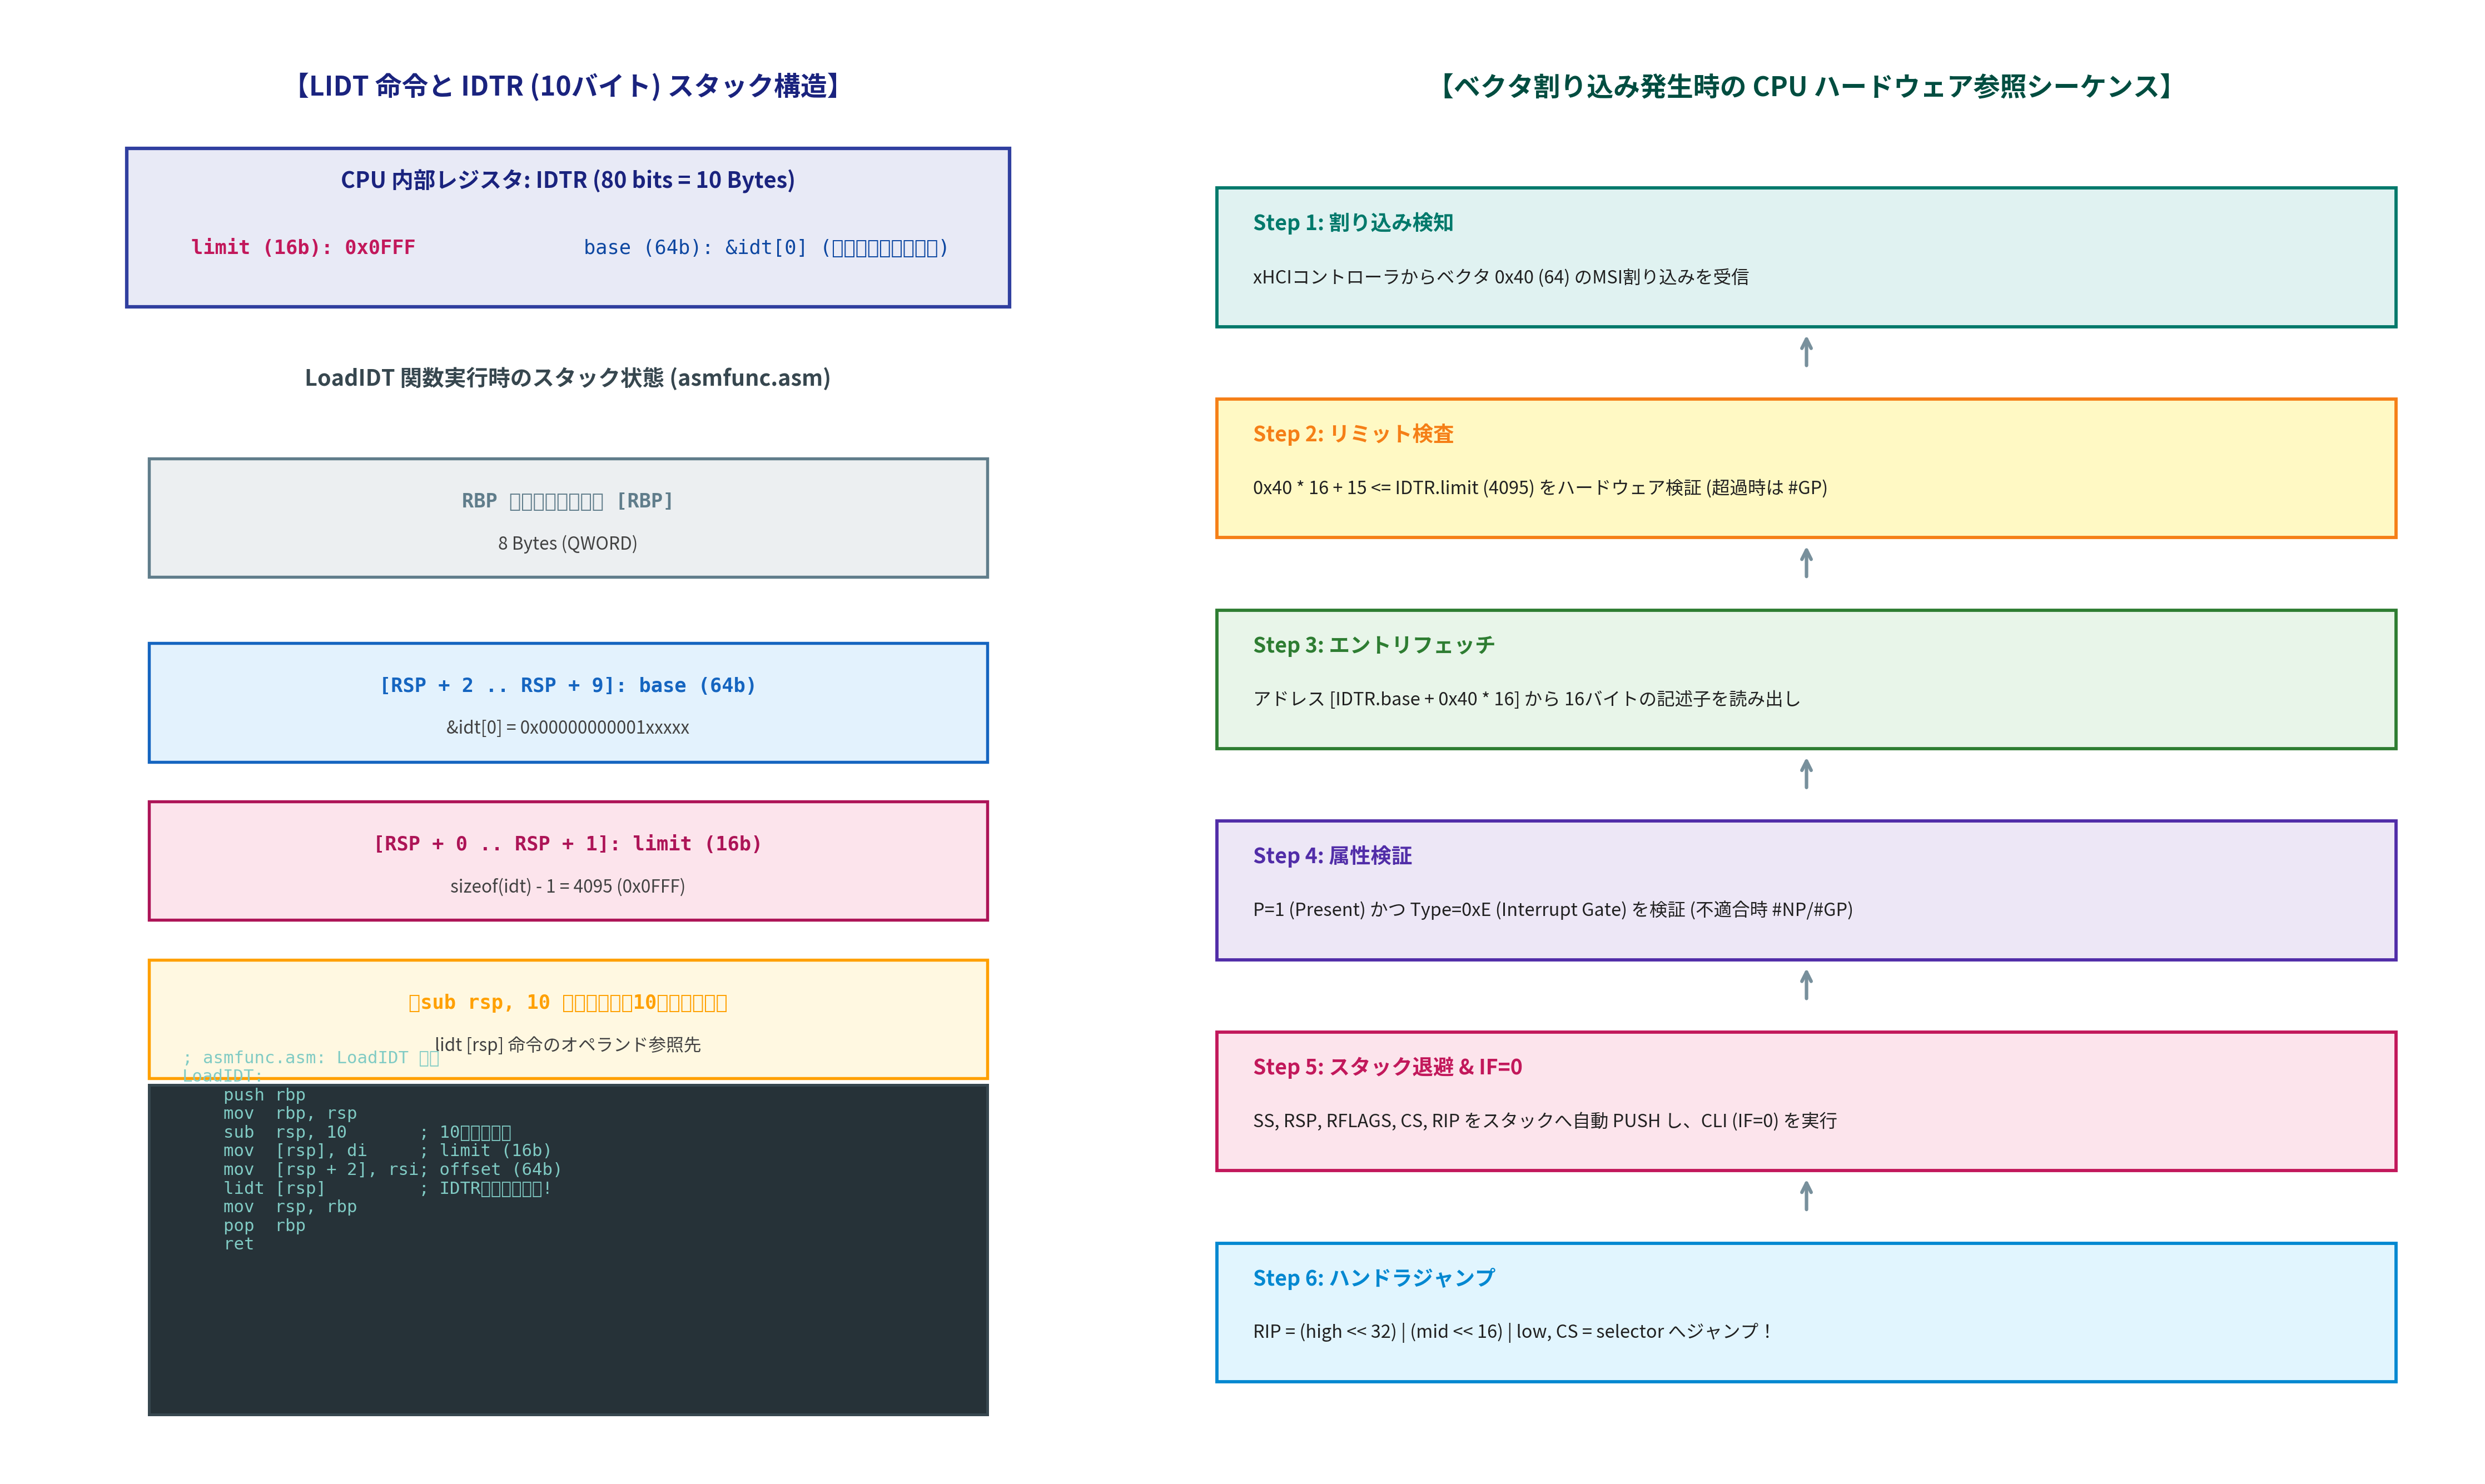

In [3]:
# === Figure 7.08: LIDT 命令スタック構造 & ハードウェアディスパッチシーケンスの生成 & 表示 ===
from pathlib import Path
from IPython.display import Image, display
from common import plot_lidt_instruction_and_vector_dispatch

fig7_08_path = Path("result/fig7_08_lidt_instruction_and_vector_dispatch.png")
plot_lidt_instruction_and_vector_dispatch(fig7_08_path)

display(Image(filename=str(fig7_08_path)))


---

## 7. MikanOS `main.cpp` での IDT 登録と xHCI 連携 (`osbook_day07a`)

ここまでの部品を組み合わせて、MikanOS のカーネル初期化コード（`kernel/main.cpp`）がどのように xHCI 割り込みハンドラを登録しているかを見てみましょう。

```cpp
// kernel/main.cpp (osbook_day07a)

// 1. 現在実行中のコードセグメントセレクタ (CS = 0x0008) を取得
const uint16_t cs = GetCS();

// 2. IDT の 0x40 番エントリ (InterruptVector::kXHCI) に xHCI ハンドラを登録
SetIDTEntry(
    idt[InterruptVector::kXHCI],                             // エントリ参照
    MakeIDTAttr(DescriptorType::kInterruptGate, 0),          // 属性: Interrupt Gate, Ring 0
    reinterpret_cast<uint64_t>(IntHandlerXHCI),              // ハンドラ先頭番地
    cs                                                       // コードセグメント
);

// 3. IDT 全体 (256エントリ, 4096バイト) を CPU の IDTR レジスタに登録
LoadIDT(sizeof(idt) - 1, reinterpret_cast<uintptr_t>(&idt[0]));
```

### 7.1 `GetCS()` アセンブリ関数 (`kernel/asmfunc.asm`)

```nasm
global GetCS  ; uint16_t GetCS(void);
GetCS:
    xor eax, eax  ; EAX全体を0クリア (上位32ビットもクリア)
    mov ax, cs    ; 現在のコードセグメントレジスタ (CS) を AX に格納
    ret
```
UEFI BIOS から制御を引き継いだ段階で、CPU の CS レジスタにはカーネルコードセグメントの値（`0x0008` 等）が設定されています。`GetCS()` で動的に取得することで、ブートローダ側の GDT 設計変更にも柔軟に対応できます。

### 7.2 CPU ハードウェアが割り込みを受信した瞬間の動作トレース

ベクタ `0x40` の MSI 割り込みが届いた瞬間、CPU 内部では以下の処理がクロック単位で自動進行します：
1. **リミット照合**: $0	ext{x}40 	imes 16 + 15 = 1039 \le 4095$ （合格）。
2. **記述子読み出し**: アドレス $	ext{IDTR.base} + 1024$ から 16 バイトをフェッチ。
3. **妥当性検証**: $	ext{Present} == 1$ かつ $	ext{Type} == 0	ext{xE}$ （合格）。
4. **スタック退避**: 割り込み前の `SS`, `RSP`, `RFLAGS`, `CS`, `RIP` をスタックへ自動 PUSH。
5. **IF フラグクリア**: Interrupt Gate のため、CPU は自動で `CLI`（二重割り込み抑止）を実行。
6. **分岐**: $	ext{CS} = 0	ext{x}0008$, $	ext{RIP} = 	ext{IntHandlerXHCI}$ に更新され、ハンドラ実行開始！


---

## 8. Python シミュレータによる IDT テーブル & ディスパッチ検証

`common/os_sim.py` の `IDTTable`, `InterruptDescriptor`, `IDTR` クラスを用いて、
- 記述子のバイナリ packing / unpacking
- 64ビットアドレスの分割と完全復元
- IDTR limit 計算と境界値チェック
- 未初期化エントリの `#NP` 例外検出
を Python 上で対話的に検証します。


In [4]:
# === Python による IDT テーブル & ディスパッチシミュレーション ===
from common import (
    DescriptorType,
    InterruptDescriptorAttribute,
    make_idt_attr,
    InterruptDescriptor,
    IDTR,
    IDTTable,
)

print("=== 1. 割り込み記述子属性のビット検証 ===")
attr = make_idt_attr(DescriptorType.kInterruptGate, descriptor_privilege_level=0, present=True, interrupt_stack_table=0)
print(f"Type: {attr.type.name} ({int(attr.type)})")
print(f"DPL:  {attr.descriptor_privilege_level}")
print(f"P:    {attr.present}")
print(f"Raw:  0x{attr.raw_value:04X} (期待値: 0x8E00)")
assert attr.raw_value == 0x8E00, "Attribute raw value must match 0x8E00"

print("\n=== 2. 64ビット仮想アドレスの 3 分割と復元 ===")
desc = InterruptDescriptor()
sample_handler_rip = 0xFFFF800000105420  # Canonical Higher-Half 仮想アドレス
kernel_cs = 0x0008

desc.attr = attr
desc.segment_selector = kernel_cs
desc.set_offset(sample_handler_rip)

print(f"元のアドレス:   0x{sample_handler_rip:016X}")
print(f"offset_low:    0x{desc.offset_low:04X} (bits 0..15)")
print(f"offset_middle: 0x{desc.offset_middle:04X} (bits 16..31)")
print(f"offset_high:   0x{desc.offset_high:08X} (bits 32..63)")
print(f"復元アドレス:   0x{desc.offset:016X}")
assert desc.offset == sample_handler_rip, "Address reconstruction failed!"

raw_16bytes = desc.to_bytes()
print(f"生バイト列 (16B): {raw_16bytes.hex(' ')}")
assert len(raw_16bytes) == 16, "Must be exactly 16 bytes"

print("\n=== 3. 256エントリ IDT テーブルと CPU ディスパッチシミュレーション ===")
table = IDTTable(256)
idtr = table.make_idtr(0x0000000000100000)
print(f"IDTR limit: {idtr.limit} (0x{idtr.limit:04X}) [256 * 16 - 1]")
print(f"IDTR base:  0x{idtr.base:016X}")
assert idtr.limit == 4095

# 未初期化エントリ 0x40 へのディスパッチ (Not Present 例外)
res_uninit = table.dispatch(0x40)
print(f"未初期化 0x40 ディスパッチ結果: success={res_uninit['success']}, error={res_uninit['error']}")
assert not res_uninit["success"]

# ベクタ 0x40 にハンドラ登録
table.set_entry(0x40, attr, sample_handler_rip, kernel_cs)
res_xhci = table.dispatch(0x40)
print(f"登録後 0x40 ディスパッチ結果: success={res_xhci['success']}, RIP=0x{res_xhci['handler_address']:016X}, CS=0x{res_xhci['segment_selector']:04X}")
assert res_xhci["success"]
assert res_xhci["handler_address"] == sample_handler_rip

print("\n✅ すべての Python IDT シミュレーション検証に合格しました！")


=== 1. 割り込み記述子属性のビット検証 ===
Type: kInterruptGate (14)
DPL:  0
P:    True
Raw:  0x8E00 (期待値: 0x8E00)

=== 2. 64ビット仮想アドレスの 3 分割と復元 ===
元のアドレス:   0xFFFF800000105420
offset_low:    0x5420 (bits 0..15)
offset_middle: 0x0010 (bits 16..31)
offset_high:   0xFFFF8000 (bits 32..63)
復元アドレス:   0xFFFF800000105420
生バイト列 (16B): 20 54 08 00 00 8e 10 00 00 80 ff ff 00 00 00 00

=== 3. 256エントリ IDT テーブルと CPU ディスパッチシミュレーション ===
IDTR limit: 4095 (0x0FFF) [256 * 16 - 1]
IDTR base:  0x0000000000100000
未初期化 0x40 ディスパッチ結果: success=False, error=NotPresent
登録後 0x40 ディスパッチ結果: success=True, RIP=0xFFFF800000105420, CS=0x0008

✅ すべての Python IDT シミュレーション検証に合格しました！


---

## 9. C++20 スタンドアロン検証コードによるメモリ構造 & 仕様の実証

ホスト側の C++20（`g++ -std=c++20`）を用いて、`src/ch07/idt_descriptor_sim.cpp` をコンパイルし、
- `sizeof(InterruptDescriptor) == 16` および `offsetof` のコンパイル時 `static_assert`
- `union InterruptDescriptorAttribute` のビットフィールド詰め合わせ
- 仮想 CPU クラスによる IDTR limit 検査とベクタ 0x40 ディスパッチ
を単体実行で検証します。


In [5]:
# === C++20 スタンドアロン検証コードのコンパイルと実行 ===
import subprocess
from pathlib import Path

repo_root = Path(".").resolve()
cpp_src = repo_root / "src/ch07/idt_descriptor_sim.cpp"
cpp_bin = repo_root / "build/bin/ch07_idt_descriptor_sim"

# CMake ビルド済みバイナリが存在しない場合は直接コンパイル
if not cpp_bin.exists():
    print(f"🔨 g++ で {cpp_src.name} をコンパイル中...")
    cpp_bin.parent.mkdir(parents=True, exist_ok=True)
    cmd_compile = ["g++", "-std=c++20", "-O2", "-Wall", "-Wextra", "-pedantic", str(cpp_src), "-o", str(cpp_bin)]
    res = subprocess.run(cmd_compile, capture_output=True, text=True)
    if res.returncode != 0:
        raise RuntimeError(f"コンパイル失敗:\n{res.stderr}")
    print("✅ コンパイル成功！")

# バイナリの実行
print(f"🚀 {cpp_bin} を実行します:\n")
res_run = subprocess.run([str(cpp_bin)], capture_output=True, text=True)
print(res_run.stdout)
assert res_run.returncode == 0, f"実行時エラー: {res_run.stderr}"


🚀 /home/student/Documents/GitHub/study-mikanos/build/bin/ch07_idt_descriptor_sim を実行します:

 MikanOS Chapter 7.4: IDT & 16-byte Gate Descriptors C++20 Verifier

[Test 1] Structure Sizes & Byte Offsets Verification...
  ✓ All sizes and offsets verified with static_assert and runtime assert.

[Test 2] InterruptDescriptorAttribute Bitfield Serialization...
  ✓ Standard kernel Interrupt Gate attribute raw value: 0x8E00 (matches 0x8E00)
  ✓ User-level Trap Gate with IST attribute raw value: 0xEF02 (matches 0xEF02)

[Test 3] 64-bit Linear Address Split and Lossless Reconstruction...
  ✓ Original Address: 0x123456789ABCDEF0
  ✓ offset_low:    0xDEF0
  ✓ offset_middle: 0x9ABC
  ✓ offset_high:   0x12345678
  ✓ Reconstructed: 0x123456789ABCDEF0
  ✓ Canonical Higher-Half address successfully tested: 0xFFFF800000102030

[Test 4] Simulated CPU IDT Loading and Vector 0x40 Dispatch...
  ✓ Uninitialized vector 0x40 correctly raises exception: #NP(Segment Not Present): Entry P bit is 0
  ✓ Configured Vec

---

## 10. 本節のまとめと次節（7.5 MSI割り込み）への展開

### 10.1 本節で学んだ最重要事項

```
【第7章 割り込みアーキテクチャの進捗】
  7.1 割り込みの概念     ── ポーリングの限界とハードウェア通知
  7.2 割り込みハンドラ   ── __attribute__((interrupt)) と IRETQ
  7.3 割り込みベクタ     ── 0x40 (64) ベクタ番号の決定
  7.4 割り込み記述子設定 ── 16バイト IDT エントリと LIDT 命令の実行  ◄──【本節完了!】
  ────────────────────────────────────────────────────────────
  7.5 MSI 割り込み       ── xHCI PCI コンフィグ空間へのベクタ登録   ◄──【次節!】
```

1. **IDT (割り込み記述子表)**:
   - 256 個の 16 バイトゲート記述子から成る配列。
   - ベクタ番号 $N$ を受けると、CPU は自動的にインデックス $N$ のエントリを参照する。
2. **16 バイトゲート記述子のビットレイアウト**:
   - 64 ビット仮想アドレスは歴史的互換性から `offset_low` (16b), `offset_middle` (16b), `offset_high` (32b) に 3 分割される。
   - MikanOS の標準割り込みゲート属性値は `0x8E00`（Present=1, DPL=0, Type=0xE Interrupt Gate）。
3. **IDTR レジスタと `LIDT` 命令**:
   - 10 バイトの構造体（`limit` 16b + `base` 64b）。
   - `limit = sizeof(idt) - 1 = 4095` (0x0FFF) は、最大有効オフセットを表す。
   - スタック上に 10 バイトを確保して `lidt [rsp]` を実行することで、CPU 内部の IDTR を一括更新。

---

### 10.2 次節への展開: 7.5 MSI 割り込み (`7/7.5_Configuring_PCI_MSI_Interrupts.ipynb`)

CPU 側の受け入れ態勢（IDT と `IntHandlerXHCI`）は完全に整いました。
しかし、**「マウスを動かしたときに、xHCI ハードウェアがベクタ 0x40 の割り込みシグナルを CPU に送信する」** ように、xHCI 側の設定を行う必要があります。

次節 **7.5 MSI 割り込み** では、
- レガシーな PIC / APIC 割り込みピン配線から **MSI (Message Signaled Interrupts)** への進化
- PCI コンフィギュレーション空間のケーパビリティリスト走査（Capability ID `0x05`）
- MSI メッセージアドレスレジスタ（`0xFEE00000` / Local APIC）とメッセージデータレジスタ（ベクタ `0x40`）の設定
を解き明かし、xHCI から CPU へのハードウェア割り込み通知を完成させます！
